In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
import scanpy as sc

adata = sc.read("./h5ad/adata_HD.h5ad")
# -----------------------------
# Configuration parameters (modify as needed)
# -----------------------------
celltypes_groupA = ["T cell", "B cell", "Myeloid cell"]
celltype_groupB = ["Stromal cell"]
gene1 = "CCR7"
gene2 = "CCL19"
group_key = "batch"          # Column name used for grouping
radii_um = np.arange(5, 81, 5)  # The unit is micrometers

# -----------------------------
# Data preprocessing
# -----------------------------
assert "spatial" in adata.obsm, "adata must have spatial coordinates in obsm['spatial']"
assert group_key in adata.obs.columns, f"'{group_key}' not found in adata.obs"
assert gene1 in adata.var_names, f"{gene1} not in adata.var_names"
assert gene2 in adata.var_names, f"{gene2} not in adata.var_names"

# Convert expression matrix to dense (compatible with sparse)
X_dense = adata.X.toarray() if hasattr(adata.X, "toarray") else np.array(adata.X)

# Get gene indices
idx_gene1 = adata.var_names.get_loc(gene1)
idx_gene2 = adata.var_names.get_loc(gene2)

# -----------------------------
# Custom colocalization score function
# -----------------------------
def compute_coloc_score(coords, mask_A, mask_B, radius_px, adata):
    """
    Calculate P(A | within radius of B) / P(A)
    Note: radius_px here must be the distance in pixel units
    """
    n_spots = len(coords)
    if mask_A.sum() == 0 or mask_B.sum() == 0:
        return np.nan

    # Find all spots within the radius neighborhood of any B
    coords_B = coords[mask_B]
    dist_to_B = cdist(coords, coords_B)  # (n_spots, n_B), unit is pixels
    in_neigh_of_B = (dist_to_B <= radius_px).any(axis=1)  # (n_spots,)

    if in_neigh_of_B.sum() == 0:
        return np.nan

    
    # Among spots in the neighborhood of B, how many are A?
    A_in_neigh = mask_A & in_neigh_of_B
    return A_in_neigh.sum() / in_neigh_of_B.sum() 

# -----------------------------
# Calculate scores grouped by effect
# -----------------------------
effect_groups = adata.obs[group_key].dropna().unique()
all_scores = {}

for group in sorted(effect_groups):
    print(f"Processing group: {group}")
    
    # Subset for the current group
    group_mask = adata.obs[group_key] == group
    sub_adata = adata[group_mask].copy()
    sub_coords = sub_adata.obsm["spatial"]
    sub_X = X_dense[group_mask]

    # Dynamically obtain the conversion factor for the current sample
    microns_per_pixel = sub_adata.uns["spatial"][group]["sample"]["scalefactors"]["microns_per_pixel"]
    
    # Convert physical micrometer radius to pixel radius
    radii_px = radii_um / microns_per_pixel

    # Build mask_A: belongs to celltypes_groupA and gene1 > 0
    mask_A = (
        sub_adata.obs["type"].isin(celltypes_groupA) &
        (sub_X[:, idx_gene1] > 0)
    )

    # Build mask_B: is Fibroblast and gene2 > 0
    mask_B = (
        sub_adata.obs["type"].isin(celltype_groupB) &
        (sub_X[:, idx_gene2] > 0)
    )

    # Calculate scores at different radii
    scores = []
    # Core fix: Iterate over the converted pixel radii
    for r_px in radii_px:
        s = compute_coloc_score(sub_coords, mask_A.values, mask_B.values, radius_px=r_px, adata = sub_adata)
        scores.append(s)
    all_scores[group] = scores

Processing group: nS01
Processing group: nS02
Processing group: nS03
Processing group: nS06


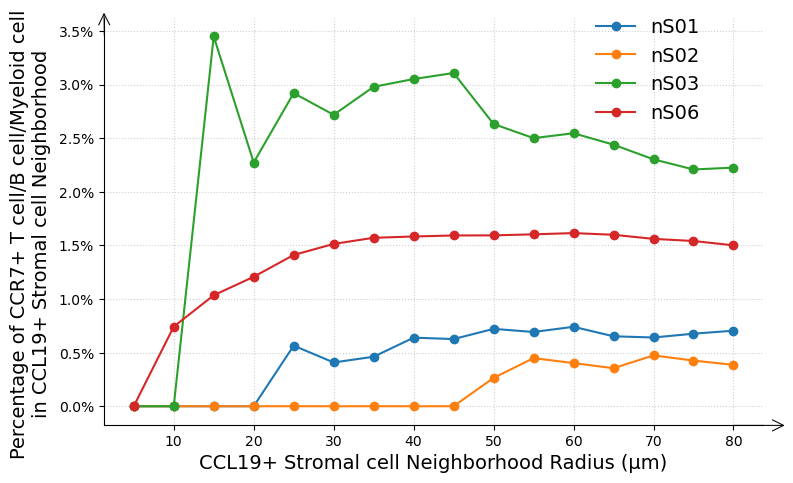

In [2]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import FancyArrowPatch

fig, ax = plt.subplots(figsize=(8, 5)) 

for group, scores in all_scores.items():
    ax.plot(radii_um, scores, marker='o', label=f"{group}")  

ax.set_xlabel(f"{gene2}+ {celltype_groupB[0]} Neighborhood Radius (µm)",fontsize = 14)
ax.set_ylabel(f"Percentage of {gene1}+ {'/'.join(celltypes_groupA)}\nin {gene2}+ {celltype_groupB[0]} Neighborhood",fontsize=14)
ax.yaxis.set_label_coords(-0.08, 0.47) 

# Hide the top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(title="",bbox_to_anchor=(0.72,0.7), frameon=False,fontsize=14)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0, decimals=1))
ax.grid(True, linestyle=":", alpha=0.6)

# Add arrows to the x- and y-axes
def add_arrow(ax, axis):
    if axis == 'x':
        arrow_start_x = ax.get_xlim()[1] - 0.05 * (ax.get_xlim()[1] - ax.get_xlim()[0])
        arrow_start_y = ax.get_ylim()[0] - 0.25/4000
        arrow_end_x = ax.get_xlim()[1] + 3
        arrow_end_y = arrow_start_y 
    elif axis == 'y':
        arrow_start_x = ax.get_xlim()[0] + 0.125 -0.05
        arrow_start_y = ax.get_ylim()[1]- 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0])
        arrow_end_x = arrow_start_x -0.05
        arrow_end_y = ax.get_ylim()[1] + 3/4000

    arrow = FancyArrowPatch((arrow_start_x, arrow_start_y),
                            (arrow_end_x, arrow_end_y),
                            arrowstyle='->',
                            mutation_scale=20,
                           clip_on=False,
                           lw=0.75)
    ax.add_patch(arrow)

add_arrow(ax, 'x')
add_arrow(ax, 'y')

plt.tight_layout()
plt.show()